# Skin lesion feature extraction (ISIC small dataset)

Pipeline: load images and masks → preprocessing (optional hair removal) → shape / colour / texture / HOG features → feature table

Input used by each feature:

- Shape features: mask only
- Colour features: original image + mask (`rgb2lab` must be applied to the original image, not after CLAHE or grayscale conversion)
- Texture features: original image → grayscale → Gaussion → GLCM + mask


#1.Imports

In [175]:
import glob, os
import numpy as np
import pandas as pd
from skimage import io, color, filters, measure, exposure, transform, img_as_ubyte, morphology
from skimage.feature import graycomatrix, graycoprops
from scipy.stats import skew, kurtosis
import matplotlib.pyplot as plt
from skimage import segmentation, measure, color
import cv2
from skimage.util import img_as_ubyte





#2.Data launch

In [176]:
from google.colab import drive
drive.mount('/content/drive')
# !find /content/drive/MyDrive -name "small_dataset*"
!unzip -o /content/small_dataset.zip -d /content/

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Archive:  /content/small_dataset.zip
  inflating: /content/SmallDataSet_GroundTruth.csv  
  inflating: /content/images/ISIC_0000000.jpg  
  inflating: /content/images/ISIC_0000001.jpg  
  inflating: /content/images/ISIC_0000002.jpg  
  inflating: /content/images/ISIC_0000004.jpg  
  inflating: /content/images/ISIC_0000006.jpg  
  inflating: /content/images/ISIC_0000007.jpg  
  inflating: /content/images/ISIC_0000008.jpg  
  inflating: /content/images/ISIC_0000009.jpg  
  inflating: /content/images/ISIC_0000010.jpg  
  inflating: /content/images/ISIC_0000011.jpg  
  inflating: /content/images/ISIC_0000016.jpg  
  inflating: /content/images/ISIC_0000017.jpg  
  inflating: /content/images/ISIC_0000026.jpg  
  inflating: /content/images/ISIC_0000029.jpg  
  inflating: /content/images/ISIC_0000030.jpg  
  inflating: /content/images/ISIC_0000031.jpg  
  inflating: 

In [177]:
!ls /content

drive	      images  sample_data		    small_dataset.zip
features.csv  masks   SmallDataSet_GroundTruth.csv


#3.Loading and display

In [178]:
# Loading images
def load_image(path):
    return io.imread(path)[..., :3]   #Remove any potential alpha channel

IMG_DIR  = "/content/images"
MASK_DIR = "/content/masks"

def load_all_images(img_dir=IMG_DIR):
    paths = sorted(glob.glob(f"{img_dir}/*.jpg"))
    images = []
    for path in paths:
        images.append(load_image(path))
    return paths, images

# Loading masks
def load_mask(img_path, mask_dir=MASK_DIR):
    name = os.path.splitext(os.path.basename(img_path))[0]     # ISIC_0000000
    candidates = sorted(glob.glob(f"{mask_dir}/{name}*"))
    mask = io.imread(candidates[0])
    return mask > 0

def load_all_masks(paths, mask_dir=MASK_DIR):
    masks = []
    for path in paths:
        masks.append(load_mask(path, mask_dir))
    return masks

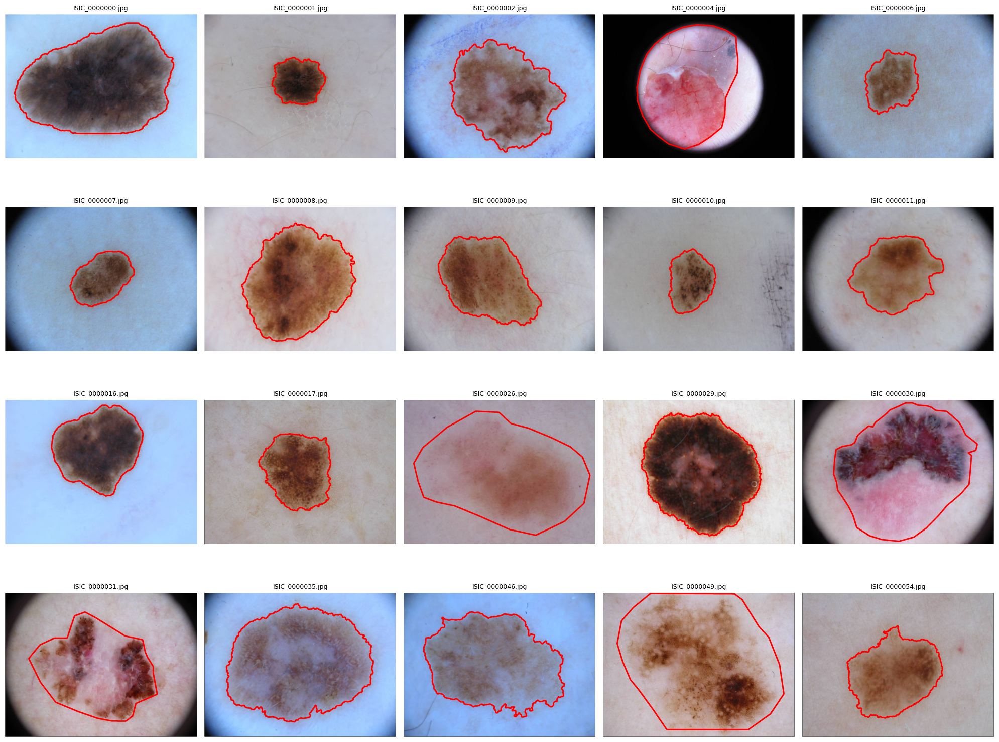

In [108]:
paths, images = load_all_images(IMG_DIR)
masks = load_all_masks(paths)

n = min(len(images), 20)
ncols = 5
nrows = (n + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows))
axes = axes.flatten()

for i in range(n):
    axes[i].imshow(images[i])
    axes[i].contour(masks[i], colors="red", linewidths=2)
    axes[i].set_title(os.path.basename(paths[i]), fontsize=9)

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

#4.Preprocessing


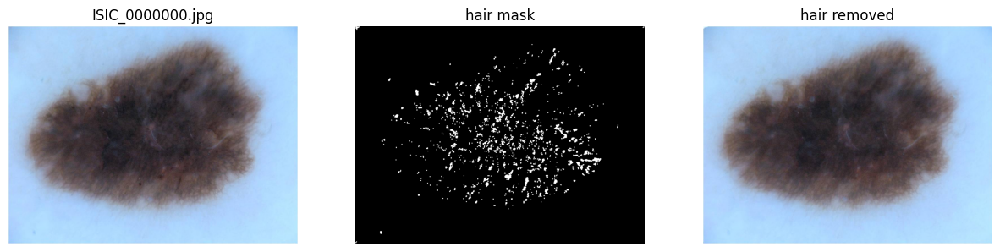

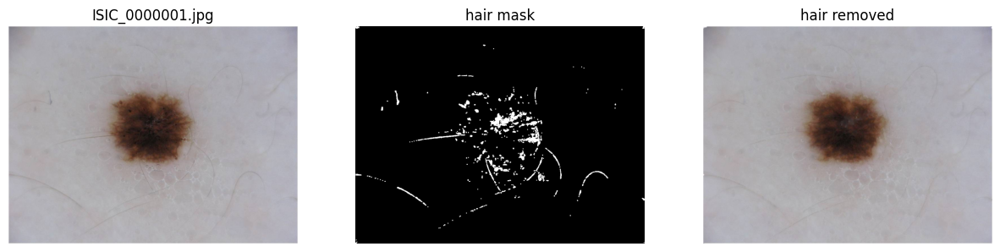

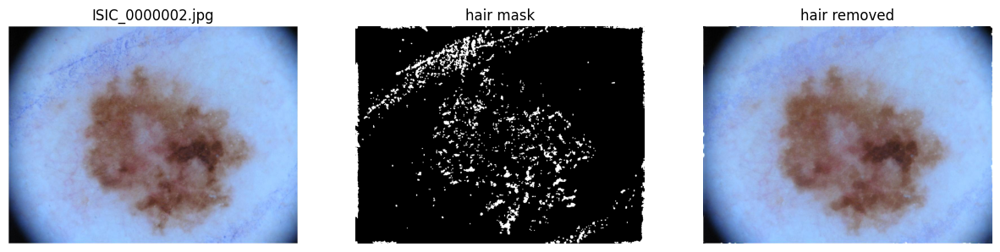

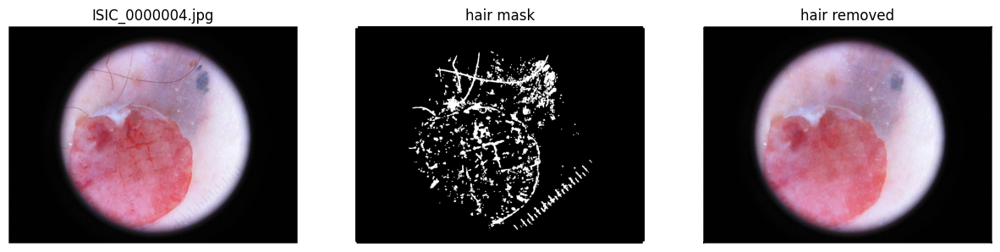

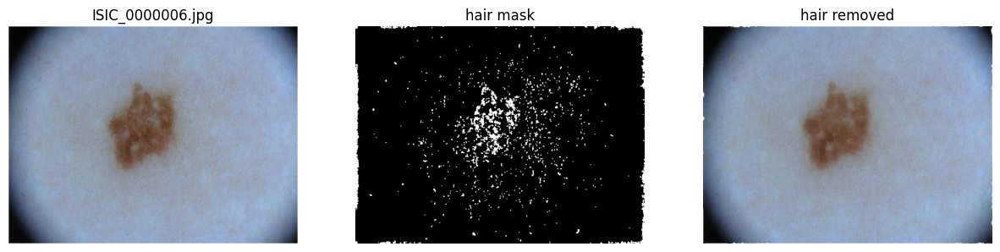

...

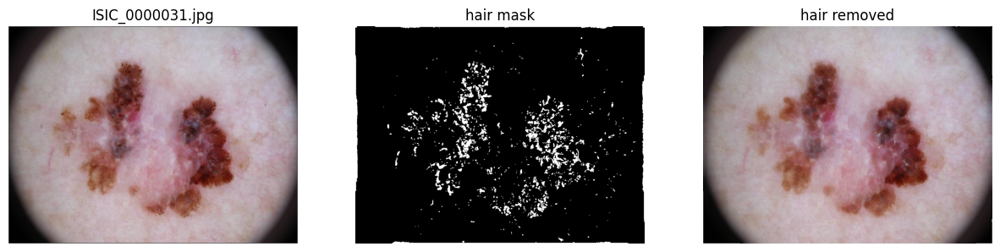

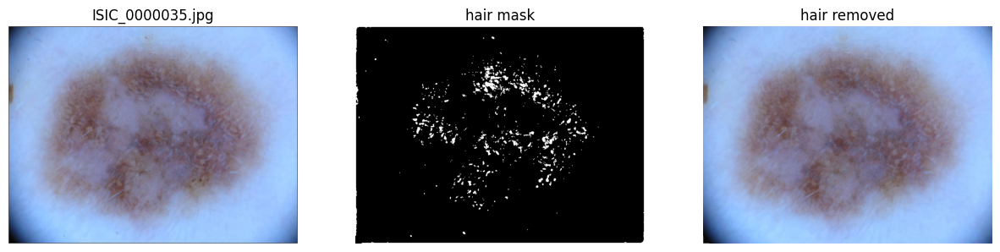

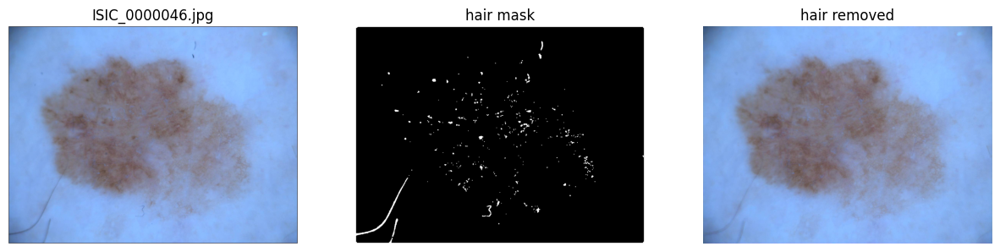

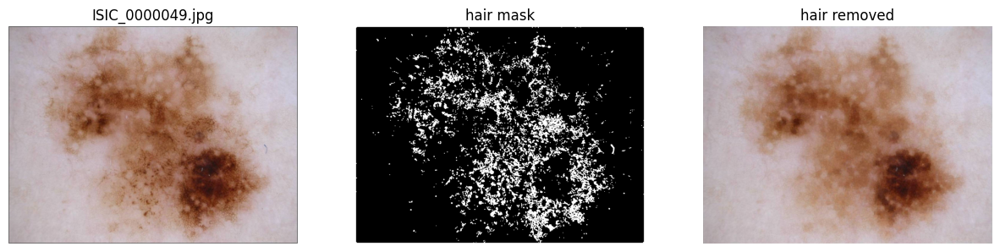

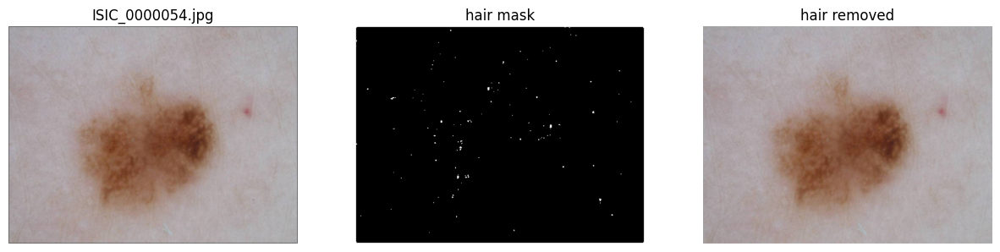

In [109]:
# def remove_hair(img, kernel_size=17, thresh=15):
#     gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
#     kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (kernel_size, kernel_size))
#     blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
#     _, hair = cv2.threshold(blackhat, thresh, 255, cv2.THRESH_BINARY)
#     hair = cv2.dilate(hair, np.ones((3, 3), np.uint8))
#     clean = cv2.inpaint(img, hair, 3, cv2.INPAINT_TELEA)
#     return clean, hair > 0


# clean_images, hair_masks = [], []
# for img in images:
#     clean, hair = remove_hair(img)
#     clean_images.append(clean)
#     hair_masks.append(hair)


# for i in range(len(images)):
#     fig, ax = plt.subplots(1, 3, figsize=(15, 4))
#     ax[0].imshow(images[i]);                  ax[0].set_title(os.path.basename(paths[i]))
#     ax[1].imshow(hair_masks[i], cmap="gray"); ax[1].set_title("hair mask")
#     ax[2].imshow(clean_images[i]);            ax[2].set_title("hair removed")
#     for a in ax:
#         a.axis("off")
#     plt.show()

This section applies hair removal, but the method is not very effective. The result depends strongly on the threshold: if it is set too low, the pigment dots inside the lesion, which are the most informative texture, are detected as hair and blurred out. If it is set too high, the hair is not removed. Thus for the following processes **this step is not used and asisted by AI**

# 5.Shape features

In [110]:
for p, img in zip(paths, images):
    print(os.path.basename(p), img.shape)


# shape features
def shape_features(mask):
    p = measure.regionprops(mask.astype(int))[0]
    return {"area": p.area, "perimeter": p.perimeter,
          "eccentricity": p.eccentricity, "solidity": p.solidity,
            "circularity": 4 * np.pi * p.area / p.perimeter ** 2}

ISIC_0000000.jpg (767, 1022, 3)
ISIC_0000001.jpg (767, 1022, 3)
ISIC_0000002.jpg (767, 1022, 3)
ISIC_0000004.jpg (767, 1022, 3)
ISIC_0000006.jpg (767, 1022, 3)
ISIC_0000007.jpg (767, 1022, 3)
ISIC_0000008.jpg (767, 1022, 3)
ISIC_0000009.jpg (767, 1022, 3)
ISIC_0000010.jpg (767, 1022, 3)
ISIC_0000011.jpg (767, 1022, 3)
ISIC_0000016.jpg (767, 1022, 3)
ISIC_0000017.jpg (1129, 1504, 3)
ISIC_0000026.jpg (1129, 1504, 3)
ISIC_0000029.jpg (1129, 1504, 3)
ISIC_0000030.jpg (1129, 1503, 3)
ISIC_0000031.jpg (1129, 1504, 3)
ISIC_0000035.jpg (1129, 1504, 3)
ISIC_0000046.jpg (1129, 1504, 3)
ISIC_0000049.jpg (1129, 1504, 3)
ISIC_0000054.jpg (1129, 1504, 3)


Shape features are computed from the mask only. Here include area, perimeter, eccentricity and solidity. Because the images come in two different resolutions, area and perimeter are not directly comparable across images. Circularity was therefore added: it is a ratio, so it does not depend on image size. It equals 1 for a perfect circle and decreases as the shape becomes more irregular.

In [88]:
rows = []
for i in range(len(images)):
    row = {"image": os.path.basename(paths[i])}
    row.update(shape_features(masks[i]))

    rows.append(row)

df = pd.DataFrame(rows)
df

,image,area,perimeter,eccentricity,solidity,circularity
0,ISIC_0000000.jpg,364956.0,2586.885569,0.757181,0.968834,0.685324
1,ISIC_0000001.jpg,53432.0,1068.915872,0.436456,0.927011,0.587657
2,ISIC_0000002.jpg,237402.0,2421.010460,0.597147,0.915687,0.508980
3,ISIC_0000004.jpg,269484.0,2014.410388,0.666933,0.986359,0.834540
4,ISIC_0000006.jpg,69455.0,1271.425540,0.620702,0.918353,0.539923
5,ISIC_0000007.jpg,67562.0,1101.200144,0.758558,0.958911,0.700132
6,ISIC_0000008.jpg,261535.0,2320.968830,0.558869,0.951732,0.610100
7,ISIC_0000009.jpg,178250.0,1975.304833,0.737711,0.944001,0.574078
8,ISIC_0000010.jpg,62087.0,1093.785930,0.694962,0.946419,0.652148
9,ISIC_0000011.jpg,139048.0,1686.788022,0.573736,0.917693,0.614120


Some masks are coarse polygons, which makes the lesion border appear more regular than it really is. Solidity and circularity are therefore limited by the annotation precision rather than reflecting the true border.

In [111]:
print(df.shape)
df.describe()

(20, 6)


,area,perimeter,eccentricity,solidity,circularity
count,2.000000e+01,20.000000,20.000000,20.000000,20.000000
mean,3.980634e+05,2580.978855,0.627440,0.947932,0.638806
std,3.214204e+05,1111.717894,0.100568,0.025757,0.119211
min,5.343200e+04,1068.915872,0.436456,0.906580,0.428564
25%,1.556898e+05,1680.308837,0.570019,0.924847,0.551208
50%,2.655095e+05,2420.545994,0.620041,0.949076,0.612110
75%,6.421592e+05,3694.541123,0.705649,0.961392,0.725948
max,1.111892e+06,4329.171065,0.793329,0.994853,0.862006


# 6.color features

In [119]:
from skimage import color

def plot_color_hist(img, mask):
    m = mask > 0
    rgb = img[m]
    lab = color.rgb2lab(img)[m]          # L: 0–100，a/b: around -100 to 100

    fig, ax = plt.subplots(1, 3, figsize=(18, 4))
    ax[0].imshow(img); ax[0].axis("off")

    for k, (name, c) in enumerate(zip(["Red", "Green", "Blue"], ["red", "green", "blue"])):
        ax[1].hist(rgb[:, k], bins=256, range=(0, 255), color=c, alpha=0.5, label=name)
    ax[1].set_title("Histograms of RGB channels inside the ROI")

    for k, (name, c) in enumerate(zip(["L", "a", "b"], ["red", "green", "blue"])):
        ax[2].hist(lab[:, k], bins=256, color=c, alpha=0.5, label=name)
    ax[2].set_title("Histograms of Lab channels inside the ROI")

    for a in ax[1:]:
        a.set_xlabel("Intensity"); a.set_ylabel("Number of pixels"); a.legend()
    plt.show()


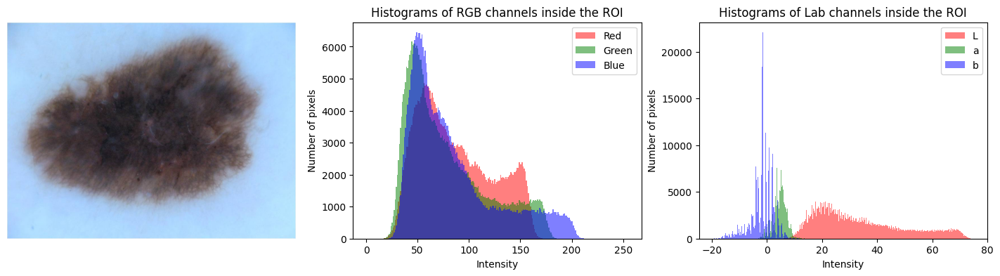

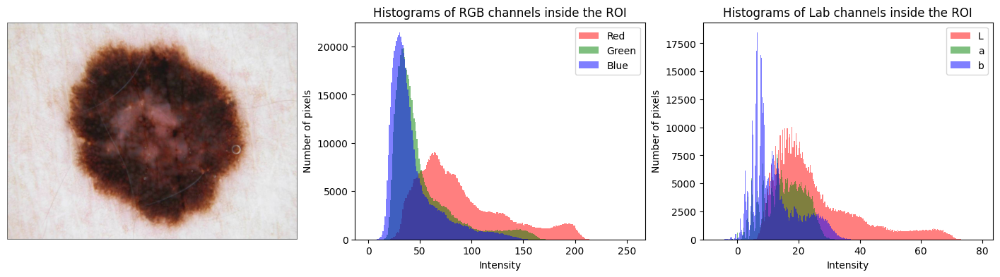

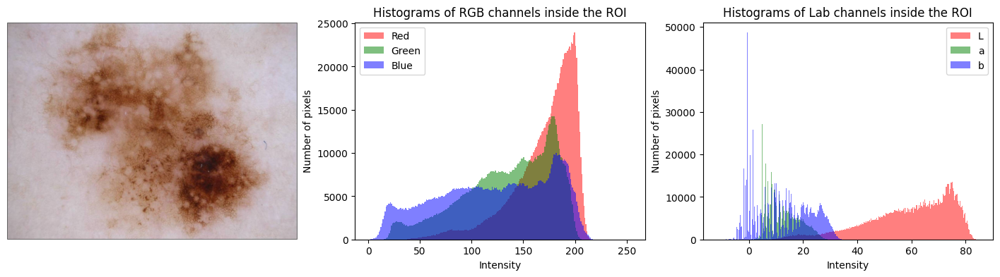

In [122]:
for name in ["ISIC_0000000.jpg", "ISIC_0000029.jpg", "ISIC_0000049.jpg"]:
    i = [os.path.basename(p) for p in paths].index(name)
    plot_color_hist(images[i], masks[i])

In [160]:
def channel_stats(pixels, names):
    rows = {}
    for k, n in enumerate(names):
        v = pixels[:, k].astype(float)
        rows[n] = {
            "Mean": v.mean(),
            "Median": np.median(v),
            "Standard deviation": v.std(),
            "First quartile": np.percentile(v, 25),
            "Third quartile": np.percentile(v, 75),
            "Skewness": skew(v),
            "Kurtosis": kurtosis(v),
        }
    return pd.DataFrame(rows).round(2)

m = masks[0] > 0
display(channel_stats(images[0][m], ["Red", "Green", "Blue"]))
display(channel_stats(color.rgb2lab(images[0])[m], ["L", "a", "b"]))

,Red,Green,Blue
Mean,86.63,78.64,84.05
Median,79.00,67.00,71.00
Standard deviation,36.08,39.25,42.78
First quartile,57.00,47.00,52.00
Third quartile,114.00,102.00,103.00
Skewness,0.44,0.87,1.11
Kurtosis,-0.94,-0.27,0.28


,L,a,b
Mean,33.79,4.65,-1.81
Median,29.71,4.87,-1.58
Standard deviation,16.13,2.33,4.21
First quartile,20.84,3.25,-3.84
Third quartile,44.25,6.18,0.83
Skewness,0.69,-0.22,-0.83
Kurtosis,-0.55,0.24,1.29


In [161]:
def color_features(img, mask):
    m = mask > 0
    feats = {}
    for pixels, channel_names in ((img[m], ["R", "G", "B"]),
                                  (color.rgb2lab(img)[m], ["Lab_L", "Lab_a", "Lab_b"])):
        for k, ch in enumerate(channel_names):
            v = pixels[:, k].astype(float)
            feats[f"{ch}_mean"]   = v.mean()
            feats[f"{ch}_median"] = np.median(v)
            feats[f"{ch}_std"]    = v.std()
            feats[f"{ch}_q1"]     = np.percentile(v, 25)
            feats[f"{ch}_q3"]     = np.percentile(v, 75)
            feats[f"{ch}_skew"]   = skew(v)
            feats[f"{ch}_kurt"]   = kurtosis(v)
    return feats

# 7.Texture features

In [126]:

PATCH_SIZE = 21

def to_uint8_gray(img):
    gray = color.rgb2gray(img)
    image = img_as_ubyte(gray)
    return image, gray


def extract_patches(image, locations, size):
    patches = []
    for loc in locations:
        patches.append(image[loc[0] : loc[0] + size, loc[1] : loc[1] + size])
    return patches

# compute some GLCM properties each patch
def glcm_features(patches):
    xs = []
    ys = []
    for patch in patches:
        glcm = graycomatrix(
            patch, distances=[5], angles=[0], levels=256, symmetric=True, normed=True
        )
        xs.append(graycoprops(glcm, 'dissimilarity')[0, 0])
        ys.append(graycoprops(glcm, 'correlation')[0, 0])
    return xs, ys

def plot_glcm(gray, nonleision_locations, leision_locations,
              nonleision_locations_patches, sky_patches, xs, ys, patch_size=PATCH_SIZE):
    fig = plt.figure(figsize=(8, 8))

    # display original image with locations of patches
    ax = fig.add_subplot(3, 2, 1)
    ax.imshow(gray, cmap=plt.cm.gray, vmin=0, vmax=255)
    for y, x in nonleision_locations:
        ax.plot(x + patch_size / 2, y + patch_size / 2, 'gs')
    for y, x in leision_locations:
        ax.plot(x + patch_size / 2, y + patch_size / 2, 'bs')
    ax.set_xlabel('Original Image')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.axis('image')

    ax = fig.add_subplot(3, 2, 2)
    ax.plot(xs[: len(nonleision_locations)], ys[: len(nonleision_locations)], 'go', label='nonleision_locations')
    ax.plot(xs[len(leision_locations) :], ys[len(leision_locations) :], 'bo', label='Sky')
    ax.set_xlabel('GLCM Dissimilarity')
    ax.set_ylabel('GLCM Correlation')
    ax.legend()

    # display the image patches
    for i, patch in enumerate(nonleision_locations_patches):
        ax = fig.add_subplot(3, len(nonleision_locations_patches), len(nonleision_locations_patches) * 1 + i + 1)
        ax.imshow(patch, cmap=plt.cm.gray, vmin=0, vmax=255)
        ax.set_xlabel(f"Grass {i + 1}")

    for i, patch in enumerate(sky_patches):
        ax = fig.add_subplot(3, len(sky_patches), len(sky_patches) * 2 + i + 1)
        ax.imshow(patch, cmap=plt.cm.gray, vmin=0, vmax=255)
        ax.set_xlabel(f"Sky {i + 1}")

    # display the patches and plot
    fig.suptitle('Grey level co-occurrence matrix features', fontsize=14, y=1.05)
    plt.tight_layout()
    plt.show()

ISIC_0000000.jpg


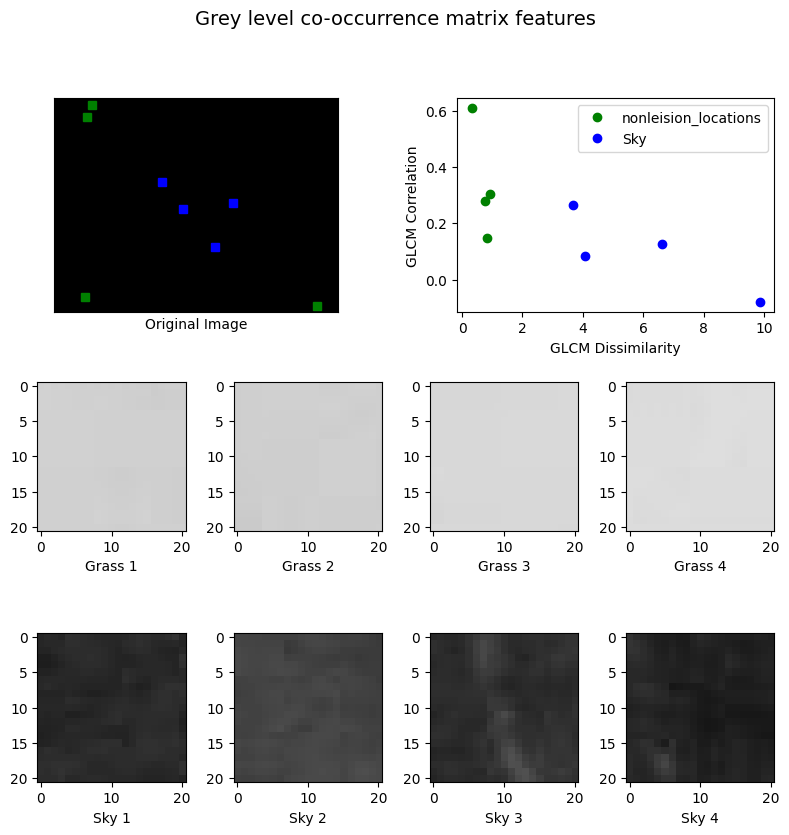

ISIC_0000026.jpg


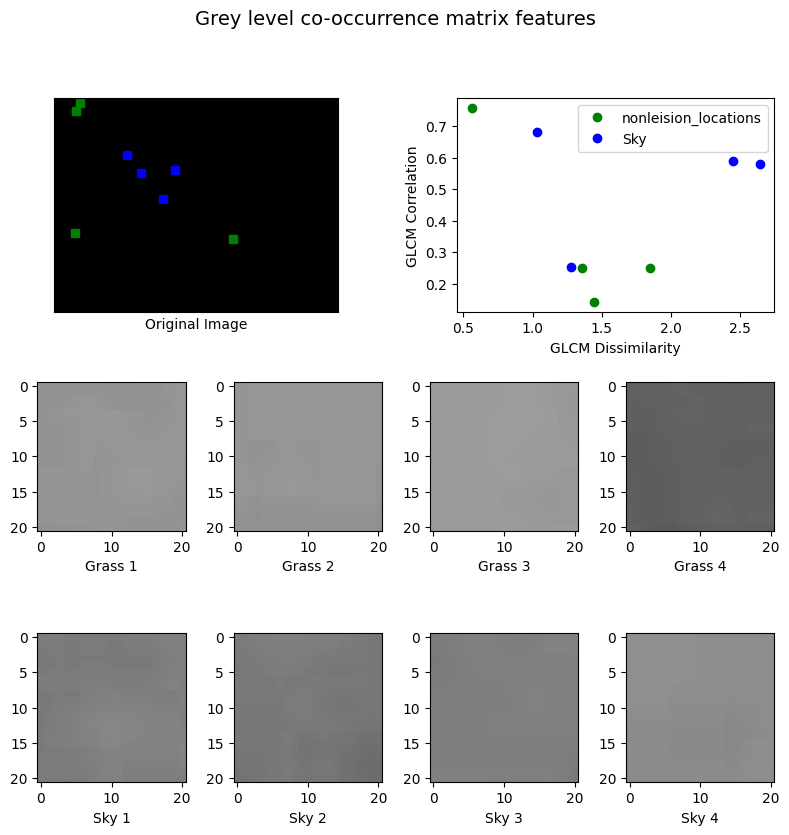

ISIC_0000030.jpg


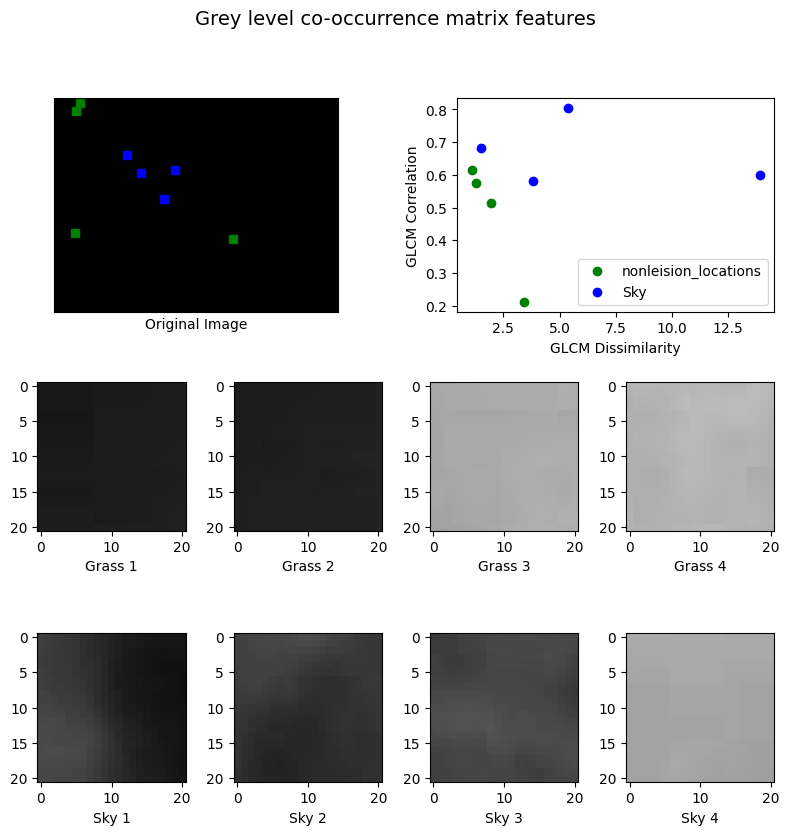

In [145]:
def run_glcm(i):
    image, gray = to_uint8_gray(images[i])

    # some patches from non_leision area of the image
    nonleision_locations = [(12, 128), (56, 108), (700, 102), (732, 935)]
    nonleision_locations_patches = extract_patches(image, nonleision_locations, PATCH_SIZE)

    # some patches from leision areas of the image
    sky_locations = [(384, 452), (522, 569), (365, 632), (289, 378)]
    sky_patches = extract_patches(image, sky_locations, PATCH_SIZE)

    xs, ys = glcm_features(nonleision_locations_patches + sky_patches)

    print(os.path.basename(paths[i]))
    plot_glcm(gray, nonleision_locations, sky_locations,
              nonleision_locations_patches, sky_patches, xs, ys)

run_glcm(0)
run_glcm(12)
run_glcm(14)

This part is refered to https://scikit-image.org/docs/stable/auto_examples/features_detection/plot_glcm.html

In [179]:
def texture_features(img, mask, levels=64, distances=(5, 10), ref_height=767):
    m = mask > 0
    gray = color.rgb2gray(img)

    #same resolution
    if gray.shape[0] != ref_height:
        new_shape = (ref_height, round(gray.shape[1] * ref_height / gray.shape[0]))
        gray = transform.resize(gray, new_shape, anti_aliasing=True)
        m = transform.resize(m, new_shape, order=0, anti_aliasing=False) > 0.5

    #light denoising
    gray = filters.gaussian(gray, sigma=0.5)

    #Cropping to speed up
    r0, c0, r1, c1 = measure.regionprops(m.astype(int))[0].bbox
    gray, m = gray[r0:r1, c0:c1], m[r0:r1, c0:c1]

    q = np.clip((gray * levels).astype(int), 0, levels - 1) + 1
    q[~m] = 0

    angles = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]
    glcm = graycomatrix(q.astype(np.uint8), distances=list(distances), angles=angles,
                        levels=levels + 1, symmetric=True, normed=False)
    glcm = glcm[1:, 1:, :, :]                                     # remove pixels related with the backrgound

    feats = {}
    for prop in ["contrast", "dissimilarity", "homogeneity", "energy", "correlation"]:
        values = graycoprops(glcm, prop).mean(axis=1)
        for d, v in zip(distances, values):
            feats[f"glcm_{prop}_d{d}"] = v
    return feats

In this case by adjusting sigma, the denoising rly doesn't do much to the texture features since the features are inherently somewhat smooth between malignant tissue and smooth tissue.

In [180]:
features = pd.DataFrame({"image": names})

features = features.join(pd.DataFrame([shape_features(m) for m in masks]))
features = features.join(pd.DataFrame([texture_features(img, m) for img, m in zip(images, masks)]))
features = features.join(pd.DataFrame([color_features(img, m) for img, m in zip(images, masks)]))

print(features.shape)     # (20, 58)
features

(20, 58)


,image,area,perimeter,eccentricity,solidity,circularity,glcm_contrast_d5,glcm_contrast_d10,glcm_dissimilarity_d5,glcm_dissimilarity_d10,...,Lab_a_q3,Lab_a_skew,Lab_a_kurt,Lab_b_mean,Lab_b_median,Lab_b_std,Lab_b_q1,Lab_b_q3,Lab_b_skew,Lab_b_kurt
0,ISIC_0000000.jpg,364956.0,2586.885569,0.757181,0.968834,0.685324,2.999803,6.281715,1.296373,1.886348,...,6.176359,-0.218678,0.240942,-1.809125,-1.577664,4.214314,-3.843127,0.827777,-0.833600,1.287152
1,ISIC_0000001.jpg,53432.0,1068.915872,0.436456,0.927011,0.587657,4.926463,9.622198,1.649924,2.351178,...,12.754085,-0.374697,-0.517982,11.484114,12.076158,5.308939,7.322119,16.101736,-0.111268,-1.082465
2,ISIC_0000002.jpg,237402.0,2421.010460,0.597147,0.915687,0.508980,3.683795,7.821030,1.442563,2.122324,...,12.852018,0.131392,-0.807233,1.919509,3.460466,7.902504,-3.067974,7.726645,-0.641334,-0.212400
3,ISIC_0000004.jpg,269484.0,2014.410388,0.666933,0.986359,0.834540,7.094370,13.419379,1.816840,2.554644,...,38.018871,0.170738,-1.358846,-3.828223,-6.225352,9.357668,-11.318094,3.734892,0.553095,-0.370313
4,ISIC_0000006.jpg,69455.0,1271.425540,0.620702,0.918353,0.539923,4.382299,8.526333,1.609556,2.278018,...,9.810518,0.018348,-1.268449,8.695395,10.809225,7.393074,2.162128,15.392199,-0.363938,-1.197652
5,ISIC_0000007.jpg,67562.0,1101.200144,0.758558,0.958911,0.700132,5.531329,10.330410,1.820513,2.516526,...,10.273155,-0.528778,-0.981533,7.833999,9.635276,5.489727,4.063995,12.092036,-0.765231,-0.338995
6,ISIC_0000008.jpg,261535.0,2320.968830,0.558869,0.951732,0.610100,3.843560,8.133415,1.477419,2.182228,...,21.227723,-0.462725,-0.643128,22.739180,23.713606,5.984919,19.421483,27.169787,-0.839200,0.429059
7,ISIC_0000009.jpg,178250.0,1975.304833,0.737711,0.944001,0.574078,3.673703,6.772810,1.425436,1.974037,...,17.542147,0.017893,-1.166791,19.027349,20.218161,4.776463,17.163675,22.283786,-1.065671,0.828394
8,ISIC_0000010.jpg,62087.0,1093.785930,0.694962,0.946419,0.652148,6.594795,13.841218,1.896118,2.816929,...,12.114751,-0.076604,-1.277886,13.782350,14.969624,3.986525,10.982509,16.900611,-0.625254,-0.633077
9,ISIC_0000011.jpg,139048.0,1686.788022,0.573736,0.917693,0.614120,1.526099,3.476009,0.898939,1.402422,...,15.116227,0.447986,-0.799233,19.082758,20.388510,5.507217,16.150142,23.173268,-0.721169,-0.169752


GLCM contrast-type features averaged over the whole lesion showed no clear association with malignancy on these 20 images (AUC very closed). This result was not sensitive to parameter choice: changing the denoising strength, the number of gray levels and the pixel distance left the ranking of the images essentially unchanged.

In [165]:
features.to_csv("features.csv", index=False)

from google.colab import files
files.download("features.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

For future classification, around 10 of the 57 features will probably be selected, since many of them are highly correlated. Colour features appear to be the most discriminative for this task.

Colour differences between images: the images were acquired with different devices and under different illumination, so some of them show a visible colour cast. This affects the colour features and could be corrected with colour normalisation (colour constancy). This was not applied here and is left as a possible improvement.